In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

df = pd.read_csv("tips.csv")
X = df[["total_bill"]]   
y = df["tip"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print(len(df), "rows;", "train:", len(X_train), "test:", len(X_test))

244 rows; train: 170 test: 74


## step 2
Models can memorize their training data. This means that scoring on data it has seen shows how well it remembers not how well it will perform on new data.

In [2]:
from sklearn.linear_model import LinearRegression

reg = LinearRegression().fit(X_train, y_train)
print("slope:    ", reg.coef_[0])
print("intercept:", reg.intercept_)
print("test R^2: ", reg.score(X_test, y_test))

slope:     0.10889370921420226
intercept: 0.8769576391532707
test R^2:  0.4291782688312412


## step 3
The slope is ~0.109, so each extra dollar of bill adds roughly 0.11 of tip.

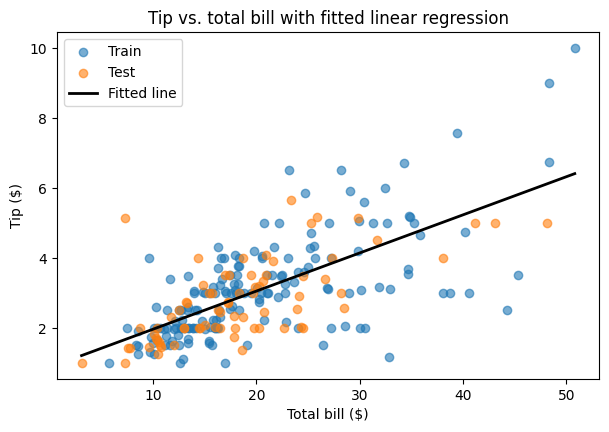

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(X_train["total_bill"], y_train, alpha=0.6, label="Train")
ax.scatter(X_test["total_bill"], y_test, alpha=0.6, label="Test")
order = X["total_bill"].argsort()
ax.plot(X["total_bill"].iloc[order], reg.predict(X).__getitem__(order), color="black", lw=2, label="Fitted line")
ax.set_xlabel("Total bill ($)")
ax.set_ylabel("Tip ($)")
ax.set_title("Tip vs. total bill with fitted linear regression")
ax.legend()
plt.show()

In [4]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
Xi, yi = iris.data, iris.target
Xi_train, Xi_test, yi_train, yi_test = train_test_split(Xi, yi, test_size=0.3, random_state=42)
print(len(Xi), "flowers;", "train:", len(Xi_train), "test:", len(Xi_test))
print(list(iris.target_names))

150 flowers; train: 105 test: 45
[np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


In [5]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5).fit(Xi_train, yi_train)
print("kNN test accuracy:", knn.score(Xi_test, yi_test))

kNN test accuracy: 1.0


depth-3 tree test accuracy: 1.0


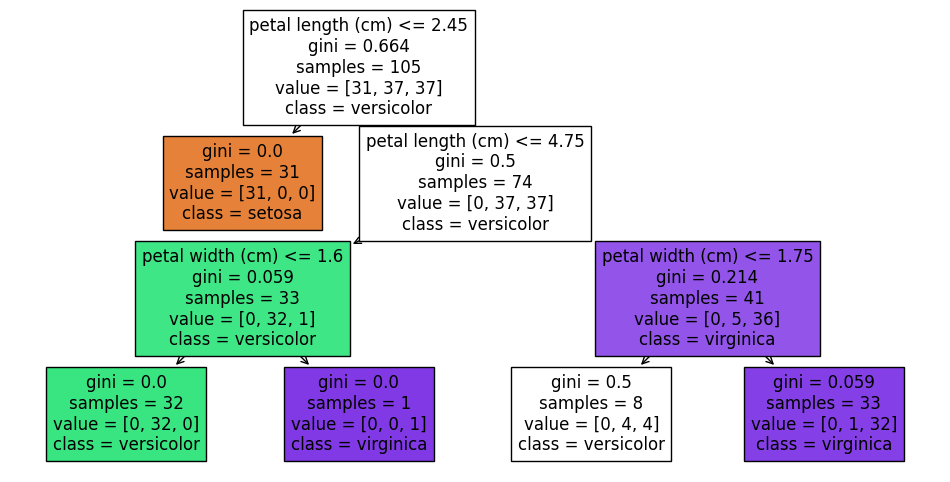

In [6]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree3 = DecisionTreeClassifier(max_depth=3, random_state=42).fit(Xi_train, yi_train)
print("depth-3 tree test accuracy:", tree3.score(Xi_test, yi_test))

plt.figure(figsize=(12, 6))
plot_tree(tree3, feature_names=iris.feature_names, class_names=list(iris.target_names), filled=True)
plt.show()

## step 7
The first question on the tree is whether petal length is less than or equal to 2.45cm. If the answer is yes then the flower is a setosa(which have smaller petals) and if it is a no then the branch does not give a final answer and more questions are asked to determine if it is a versicolor or virginica.

In [7]:
tree_full = DecisionTreeClassifier(random_state=42).fit(Xi_train, yi_train)

results = pd.DataFrame({
    "model": ["max_depth=3", "no max_depth"],
    "train score": [tree3.score(Xi_train, yi_train), tree_full.score(Xi_train, yi_train)],
    "test score": [tree3.score(Xi_test, yi_test), tree_full.score(Xi_test, yi_test)],
    "depth": [tree3.get_depth(), tree_full.get_depth()],
})
print(results.to_string(index=False))

       model  train score  test score  depth
 max_depth=3     0.952381         1.0      3
no max_depth     1.000000         1.0      6


## step 8
The trees have different scores on train(3-depth tree score on train is 0.95 and the unlimited has 1.00), but they both have 1.00 on test, which means that the extra depth is just memorizing training data.

In [8]:
new_flower = pd.DataFrame([[6.1, 2.9, 4.5, 1.4]], columns=iris.feature_names)  
pred = tree3.predict(new_flower)[0]
print("Predicted species:", iris.target_names[pred])

Predicted species: versicolor


## step 10
Sepal and petal measurements are used by the model to predict the species of flower. The 3 depth tree scored 1.00 on the test set. I would ship that one because it ties kNN and the full tree on test but is simpler and less prone to memorizing noise. For borderline versicolor/virginica flowers it may fail. Because there are only 45 test flowers the score of 1.00 may not be the most accurate. When groups are underrepresented in data, predictions about those groups tend to be worse, so if it were about people there could be inaccurate predictions and more biased decisions with those that are underrepresented.  